# **Colorectol Cancer**

**Awo Abdillahi**
1001911900

In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import sys

print("Python:", sys.version.split()[0])
print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("Seaborn:", sns.__version__)

Path("data").mkdir(exist_ok=True)
Path("results").mkdir(exist_ok=True)
Path("figures").mkdir(exist_ok=True)

Python: 3.13.18
Pandas: 2.2.3
NumPy: 2.4.6
Seaborn: 0.13.2


In [2]:

from urllib.request import urlretrieve
import tarfile

url = (
    "https://ftp.ncbi.nlm.nih.gov/geo/series/"
    "GSE50nnn/GSE50760/suppl/GSE50760_RAW.tar"
)

archive = Path("data/GSE50760_RAW.tar")
folder = Path("data/GSE50760")
folder.mkdir(exist_ok=True)

if not archive.exists():
    urlretrieve(url, archive)

with tarfile.open(archive, "r") as tar:
    members = [
        m for m in tar.getmembers()
        if m.isfile() and m.name.endswith(".txt.gz")
    ]

    # Extract only filenames without directory paths
    for member in members:
        target = folder / Path(member.name).name
        with tar.extractfile(member) as source:
            target.write_bytes(source.read())

files = sorted(folder.glob("*.txt.gz"))

print("Number of expression files:", len(files))
print("First five files:")
for file in files[:5]:
    print(file.name)

assert len(files) == 54, "Expected 54 sample files"


Number of expression files: 54
First five files:
GSM1228184_AMC_2.1_FPKM.txt.gz
GSM1228185_AMC_3.1_FPKM.txt.gz
GSM1228186_AMC_5.1_FPKM.txt.gz
GSM1228187_AMC_6.1_FPKM.txt.gz
GSM1228188_AMC_7.1_FPKM.txt.gz


In [3]:

example = pd.read_csv(
    files[0],
    sep="\t",
    compression="gzip"
)

print("Dimensions:", example.shape)
print("Column names:", example.columns.tolist())
print("Data types:")
print(example.dtypes)

display(example.head())


Dimensions: (23505, 2)
Column names: ['genes', 'AMC_2.1_FPKM']
Data types:
genes            object
AMC_2.1_FPKM    float64
dtype: object


,genes,AMC_2.1_FPKM
0,A1BG,0.241109
1,A1BG-AS1,0.028173
2,A1CF,16.257000
3,A2LD1,1.566140
4,A2M,33.146900


In [4]:

import re

metadata = []

for file in files:
    match = re.search(
        r"AMC_(\d+)[._-]([123])",
        file.name
    )

    if match is None:
        raise ValueError(
            f"Unexpected filename: {file.name}"
        )

    patient_id = match.group(1)
    sample_type = match.group(2)

    condition = {
        "1": "Tumor",
        "2": "Normal",
        "3": "Metastasis"
    }[sample_type]

    metadata.append({
        "filename": file.name,
        "patient_id": patient_id,
        "condition": condition
    })

sample_info = pd.DataFrame(metadata)

# Focus on primary tumors and normal tissue
sample_info = sample_info[
    sample_info["condition"].isin(
        ["Tumor", "Normal"]
    )
].copy()

pair_counts = pd.crosstab(
    sample_info["patient_id"],
    sample_info["condition"]
)

assert len(sample_info) == 36
assert len(pair_counts) == 18
assert (pair_counts[["Tumor", "Normal"]] == 1).all().all()

sample_info.to_csv(
    "results/sample_metadata.csv",
    index=False
)

display(sample_info.head(10))
print(pair_counts)
print("Validated patient pairs:", len(pair_counts))


,filename,patient_id,condition
0,GSM1228184_AMC_2.1_FPKM.txt.gz,2,Tumor
1,GSM1228185_AMC_3.1_FPKM.txt.gz,3,Tumor
2,GSM1228186_AMC_5.1_FPKM.txt.gz,5,Tumor
3,GSM1228187_AMC_6.1_FPKM.txt.gz,6,Tumor
4,GSM1228188_AMC_7.1_FPKM.txt.gz,7,Tumor
5,GSM1228189_AMC_8.1_FPKM.txt.gz,8,Tumor
6,GSM1228190_AMC_9.1_FPKM.txt.gz,9,Tumor
7,GSM1228191_AMC_10.1_FPKM.txt.gz,10,Tumor
8,GSM1228192_AMC_12.1_FPKM.txt.gz,12,Tumor
9,GSM1228193_AMC_13.1_FPKM.txt.gz,13,Tumor


condition   Normal  Tumor
patient_id               
10               1      1
12               1      1
13               1      1
17               1      1
18               1      1
19               1      1
2                1      1
20               1      1
21               1      1
22               1      1
23               1      1
24               1      1
3                1      1
5                1      1
6                1      1
7                1      1
8                1      1
9                1      1
Validated patient pairs: 18


In [5]:

expression_data = []

for _, row in sample_info.iterrows():
    file_path = folder / row["filename"]

    df = pd.read_csv(
        file_path,
        sep="\t",
        compression="gzip"
    )

    sample_name = f'{row["patient_id"]}_{row["condition"]}'

    df = df.set_index("genes")

    if df.index.duplicated().any():
        raise ValueError(f"Duplicate genes in {file_path}")

    df.columns = [sample_name]

    expression_data.append(df)

expression_matrix = pd.concat(expression_data, axis=1)

print("Expression matrix dimensions:", expression_matrix.shape)

display(expression_matrix.head())


ValueError: Duplicate genes in data/GSE50760/GSM1228184_AMC_2.1_FPKM.txt.gz

In [6]:
duplicate_genes = example[
    example["genes"].duplicated(keep=False)
]

print("Number of duplicate entries:", len(duplicate_genes))

print("Number of affected gene names:",
      duplicate_genes["genes"].nunique())

display(duplicate_genes.sort_values("genes"))

Number of duplicate entries: 4
Number of affected gene names: 2


,genes,AMC_2.1_FPKM
11732,01-Mar,11.18600
11734,01-Mar,1.51465
11733,02-Mar,5.40036
11737,02-Mar,5.97777


In [7]:
date_pattern = (
    r"(?i)^(?:\d{1,2}-"
    r"(Jan|Feb|Mar|Apr|May|Jun|Jul|Aug|Sep|Oct|Nov|Dec))$"
)

corrupted_genes = example[
    example["genes"].str.contains(
        date_pattern.replace("(", "(?:", 1)
        if False else date_pattern.replace("(Jan", "(?:Jan"),
        regex=True,
        na=False
    )
]

print("Number of corrupted entries:", len(corrupted_genes))

display(corrupted_genes)

Number of corrupted entries: 28


,genes,AMC_2.1_FPKM
4643,01-Dec,0.000000
11732,01-Mar,11.186000
11733,02-Mar,5.400360
11734,01-Mar,1.514650
11735,10-Mar,0.014424
11736,11-Mar,0.000000
11737,02-Mar,5.977770
11738,03-Mar,1.748980
11739,04-Mar,0.041134
11740,05-Mar,16.464400


In [8]:
expression_data = []
cleaning_summary = []

date_pattern = (
    r"(?i)^\d{1,2}-"
    r"(?:Jan|Feb|Mar|Apr|May|Jun|Jul|Aug|Sep|Oct|Nov|Dec)$"
)

for _, row in sample_info.iterrows():

    file_path = folder / row["filename"]

    df = pd.read_csv(
        file_path,
        sep="\t",
        compression="gzip"
    )

    sample_name = f'{row["patient_id"]}_{row["condition"]}'

    # Identify corrupted and duplicate gene identifiers
    date_mask = df["genes"].str.match(date_pattern, na=False)
    duplicate_mask = df["genes"].duplicated(keep=False)
    missing_mask = df["genes"].isna()

    remove_mask = date_mask | duplicate_mask | missing_mask

    # Record data cleaning statistics
    cleaning_summary.append({
        "Sample": sample_name,
        "Original_Rows": len(df),
        "Corrupted_Entries": date_mask.sum(),
        "Duplicate_Entries": duplicate_mask.sum(),
        "Removed_Entries": remove_mask.sum(),
        "Retained_Entries": (~remove_mask).sum()
    })

    # Remove ambiguous gene identifiers
    df = df[~remove_mask].copy()

    df = df.set_index("genes")
    df.columns = [sample_name]

    expression_data.append(df)

# Combine genes shared across all samples
expression_matrix = pd.concat(
    expression_data,
    axis=1,
    join="inner"
)

cleaning_summary = pd.DataFrame(cleaning_summary)

display(cleaning_summary)
display(expression_matrix.head())

print("Expression matrix dimensions:",
      expression_matrix.shape)

,Sample,Original_Rows,Corrupted_Entries,Duplicate_Entries,Removed_Entries,Retained_Entries
0,2_Tumor,23505,28,4,28,23477
1,3_Tumor,23505,28,4,28,23477
2,5_Tumor,23505,28,4,28,23477
3,6_Tumor,23505,28,4,28,23477
4,7_Tumor,23505,28,4,28,23477
5,8_Tumor,23505,28,4,28,23477
6,9_Tumor,23505,28,4,28,23477
7,10_Tumor,23505,28,4,28,23477
8,12_Tumor,23505,28,4,28,23477
9,13_Tumor,23505,28,4,28,23477


,2_Tumor,3_Tumor,5_Tumor,6_Tumor,7_Tumor,8_Tumor,9_Tumor,10_Tumor,12_Tumor,13_Tumor,...,12_Normal,13_Normal,17_Normal,18_Normal,19_Normal,20_Normal,21_Normal,22_Normal,23_Normal,24_Normal
genes,,,,,,,,,,,,,,,,,,,,,
A1BG,0.241109,0.413634,0.773777,0.290182,0.508287,0.33136,1.262380,0.698841,0.887596,1.206880,...,1.224210,1.184170,0.398219,0.914008,1.095240,0.728298,0.791864,1.025330,1.128390,1.269370
A1BG-AS1,0.028173,0.021606,0.149216,0.054038,0.083540,0.03093,0.212198,0.132871,0.055595,0.097827,...,0.044651,0.145363,0.023945,0.130440,0.143121,0.168976,0.105128,0.239548,0.063037,0.116729
A1CF,16.257000,12.422300,4.637920,4.212960,5.013990,6.71257,0.053631,2.912700,3.028930,4.517850,...,6.486870,7.088190,2.324710,4.146690,5.112840,6.112250,8.656090,8.721800,8.594680,5.439890
A2LD1,1.566140,4.625220,3.556490,6.135820,6.769770,4.26363,1.679220,4.565250,4.775300,3.438030,...,4.037580,5.288050,1.978690,3.215050,2.948590,3.108900,2.885620,3.190030,3.420250,10.877300
A2M,33.146900,46.837500,114.636000,37.306200,22.565800,69.74010,399.887000,76.089500,78.800800,76.992300,...,111.915000,105.835000,97.263700,41.536400,110.674000,85.462400,75.652500,95.138500,78.787800,109.087000


Expression matrix dimensions: (23477, 36)


In [9]:
print("Total samples:", expression_matrix.shape[1])

print("Total retained genes:", expression_matrix.shape[0])

print("Missing values:",
      expression_matrix.isna().sum().sum())

print("Remaining duplicate genes:",
      expression_matrix.index.duplicated().sum())

print("Negative expression values:",
      (expression_matrix < 0).sum().sum())

print("Infinite values:",
      np.isinf(expression_matrix).sum().sum())

display(cleaning_summary.describe())

Total samples: 36
Total retained genes: 23477
Missing values: 0
Remaining duplicate genes: 0
Negative expression values: 0
Infinite values: 0


,Original_Rows,Corrupted_Entries,Duplicate_Entries,Removed_Entries,Retained_Entries
count,36.0,36.0,36.0,36.0,36.0
mean,23505.0,28.0,4.0,28.0,23477.0
std,0.0,0.0,0.0,0.0,0.0
min,23505.0,28.0,4.0,28.0,23477.0
25%,23505.0,28.0,4.0,28.0,23477.0
50%,23505.0,28.0,4.0,28.0,23477.0
75%,23505.0,28.0,4.0,28.0,23477.0
max,23505.0,28.0,4.0,28.0,23477.0


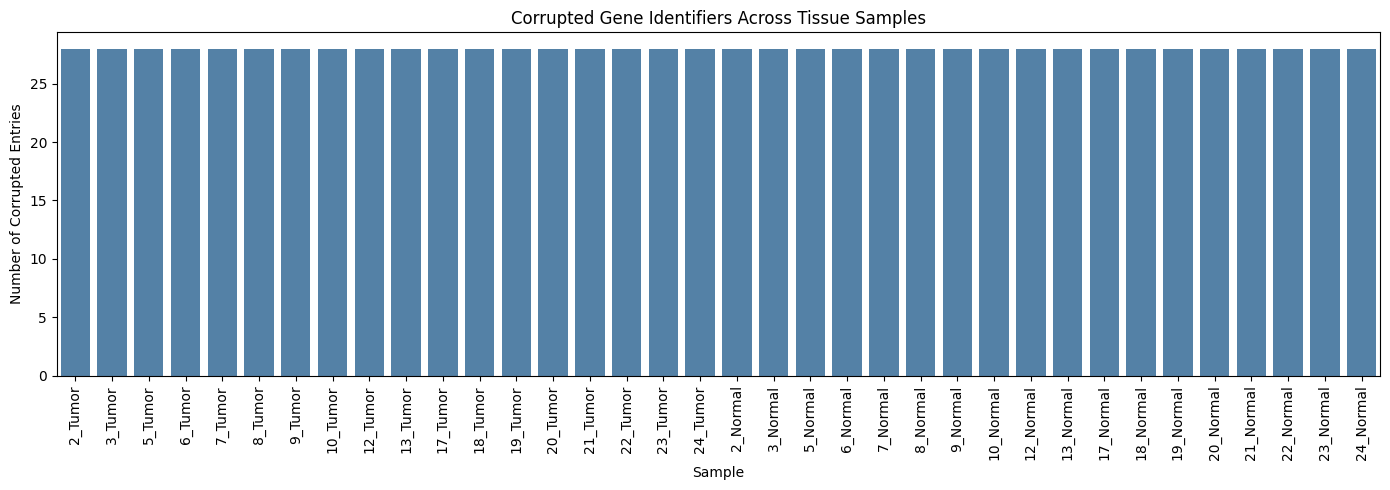

In [10]:
plt.figure(figsize=(14, 5))

sns.barplot(
    data=cleaning_summary,
    x="Sample",
    y="Corrupted_Entries",
    color="steelblue"
)

plt.title("Corrupted Gene Identifiers Across Tissue Samples")
plt.xlabel("Sample")
plt.ylabel("Number of Corrupted Entries")
plt.xticks(rotation=90)
plt.tight_layout()

plt.savefig(
    "figures/corrupted_gene_identifiers.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [11]:
filtered_matrix = expression_matrix[
    (expression_matrix >= 1).sum(axis=1) >= 18
].copy()

original_genes = expression_matrix.shape[0]
retained_genes = filtered_matrix.shape[0]
removed_genes = original_genes - retained_genes

print("Genes before filtering:", original_genes)
print("Genes after filtering:", retained_genes)
print("Genes removed:", removed_genes)

print(f"Percentage retained: {retained_genes / original_genes:.2%}")

display(filtered_matrix.head())

Genes before filtering: 23477
Genes after filtering: 12803
Genes removed: 10674
Percentage retained: 54.53%


,2_Tumor,3_Tumor,5_Tumor,6_Tumor,7_Tumor,8_Tumor,9_Tumor,10_Tumor,12_Tumor,13_Tumor,...,12_Normal,13_Normal,17_Normal,18_Normal,19_Normal,20_Normal,21_Normal,22_Normal,23_Normal,24_Normal
genes,,,,,,,,,,,,,,,,,,,,,
A1CF,16.25700,12.42230,4.63792,4.21296,5.01399,6.71257,0.053631,2.91270,3.02893,4.51785,...,6.48687,7.08819,2.32471,4.14669,5.11284,6.11225,8.65609,8.72180,8.59468,5.43989
A2LD1,1.56614,4.62522,3.55649,6.13582,6.76977,4.26363,1.679220,4.56525,4.77530,3.43803,...,4.03758,5.28805,1.97869,3.21505,2.94859,3.10890,2.88562,3.19003,3.42025,10.87730
A2M,33.14690,46.83750,114.63600,37.30620,22.56580,69.74010,399.887000,76.08950,78.80080,76.99230,...,111.91500,105.83500,97.26370,41.53640,110.67400,85.46240,75.65250,95.13850,78.78780,109.08700
A4GALT,0.70743,1.01500,3.55672,3.07267,1.03725,1.95626,19.014400,2.86280,4.11791,4.68350,...,2.66205,2.11759,11.02800,2.55486,2.73374,2.43189,1.58112,2.45795,2.28539,4.08489
AAAS,21.32540,11.49890,10.48270,12.31030,13.22830,14.27230,16.970100,13.27780,14.43220,13.35370,...,11.26130,9.81745,17.95280,13.80340,11.70470,11.71780,11.18340,11.51540,9.95022,14.73060


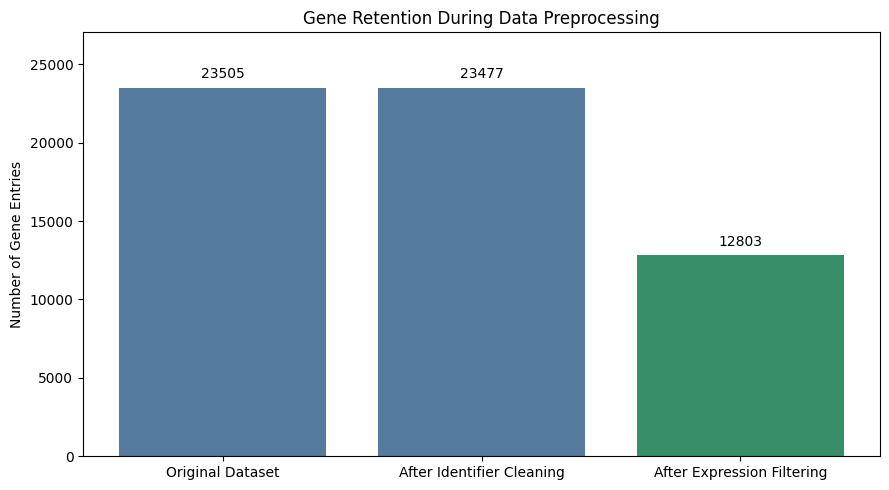

In [12]:
stages = [
    "Original Dataset",
    "After Identifier Cleaning",
    "After Expression Filtering"
]

counts = [
    23505,
    expression_matrix.shape[0],
    filtered_matrix.shape[0]
]

plt.figure(figsize=(9, 5))

bars = plt.bar(
    stages,
    counts,
    color=["#547A9E", "#547A9E", "#388E68"]
)

plt.bar_label(bars, fmt="%d", padding=5)

plt.title("Gene Retention During Data Preprocessing")
plt.ylabel("Number of Gene Entries")
plt.ylim(0, max(counts) * 1.15)
plt.tight_layout()

plt.savefig(
    "figures/gene_retention.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [13]:
log_matrix = np.log2(filtered_matrix + 1)

print("Transformed matrix dimensions:", log_matrix.shape)

display(log_matrix.head())

log_matrix.to_csv(
    "results/processed_expression_matrix.csv"
)

Transformed matrix dimensions: (12803, 36)


,2_Tumor,3_Tumor,5_Tumor,6_Tumor,7_Tumor,8_Tumor,9_Tumor,10_Tumor,12_Tumor,13_Tumor,...,12_Normal,13_Normal,17_Normal,18_Normal,19_Normal,20_Normal,21_Normal,22_Normal,23_Normal,24_Normal
genes,,,,,,,,,,,,,,,,,,,,,
A1CF,4.109110,3.746560,2.495163,2.382103,2.588322,2.947212,0.075370,1.968164,2.010397,2.464106,...,2.904363,3.015817,1.733229,2.363645,2.611843,2.830306,3.271439,3.281223,3.262235,2.687036
A2LD1,1.359600,2.491910,2.187923,2.835079,2.957872,2.396058,1.421813,2.476446,2.529896,2.149919,...,2.332731,2.652613,1.574678,2.075550,1.981338,2.038752,1.958145,2.066961,2.144128,3.570135
A2M,5.093683,5.580070,6.853447,5.259506,4.558623,6.144456,8.647052,6.268462,6.318331,6.285260,...,6.819093,6.739241,6.618587,5.410626,6.803150,6.434001,6.260261,6.587042,6.318096,6.782500
A4GALT,0.771826,1.010780,2.187996,2.025975,1.026623,1.563773,4.322966,1.949647,2.355555,2.506780,...,1.872651,1.640431,3.588325,1.829793,1.900621,1.779003,1.367997,1.789917,1.716065,2.346217
AAAS,4.480614,3.643729,3.521390,3.734471,3.830691,3.932845,4.167527,3.835702,3.947872,3.843351,...,3.616040,3.435289,4.244339,3.887857,3.667290,3.668777,3.606845,3.645632,3.452888,3.975502


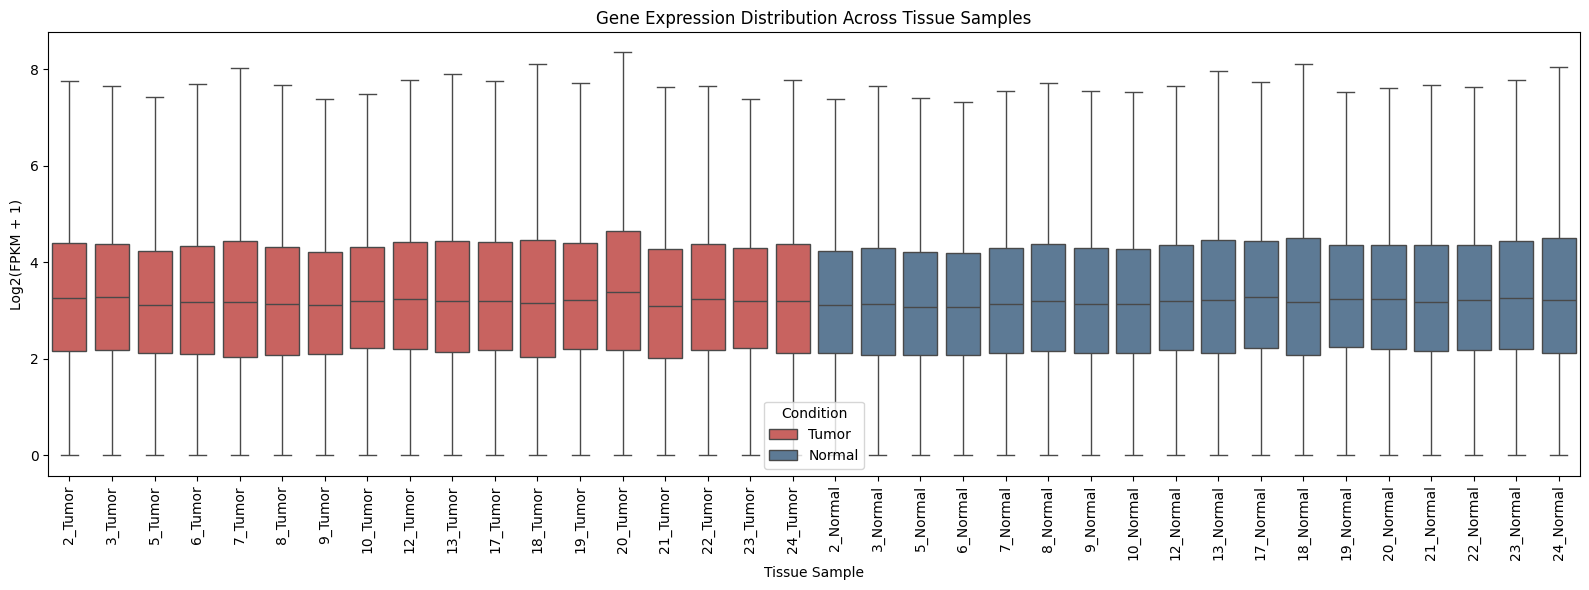

In [14]:
plot_data = log_matrix.melt(
    var_name="Sample",
    value_name="Expression"
)

plot_data["Condition"] = (
    plot_data["Sample"].str.split("_").str[-1]
)

plt.figure(figsize=(16, 6))

sns.boxplot(
    data=plot_data,
    x="Sample",
    y="Expression",
    hue="Condition",
    palette={
        "Tumor": "#D9534F",
        "Normal": "#547A9E"
    },
    showfliers=False,
    dodge=False
)

plt.title("Gene Expression Distribution Across Tissue Samples")
plt.xlabel("Tissue Sample")
plt.ylabel("Log2(FPKM + 1)")
plt.xticks(rotation=90)
plt.tight_layout()

plt.savefig(
    "figures/expression_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

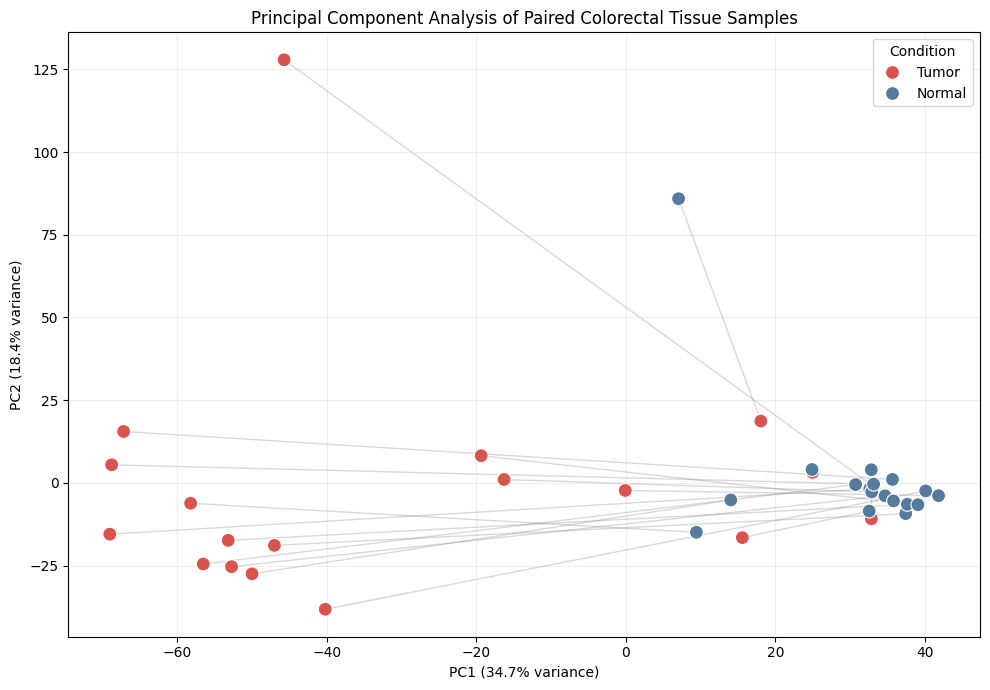

In [15]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2)

pca_results = pca.fit_transform(log_matrix.T)

pca_df = pd.DataFrame(
    pca_results,
    columns=["PC1", "PC2"]
)

pca_df["Sample"] = log_matrix.columns

pca_df["Condition"] = (
    pca_df["Sample"].str.split("_").str[-1]
)

pca_df["Patient"] = (
    pca_df["Sample"].str.split("_").str[0]
)

plt.figure(figsize=(10, 7))

# Connect samples from the same patient
for patient, group in pca_df.groupby("Patient"):
    plt.plot(
        group["PC1"],
        group["PC2"],
        color="gray",
        alpha=0.3,
        linewidth=1,
        zorder=1
    )

sns.scatterplot(
    data=pca_df,
    x="PC1",
    y="PC2",
    hue="Condition",
    palette={
        "Tumor": "#D9534F",
        "Normal": "#547A9E"
    },
    s=100,
    zorder=2
)

plt.xlabel(
    f"PC1 ({pca.explained_variance_ratio_[0]:.1%} variance)"
)

plt.ylabel(
    f"PC2 ({pca.explained_variance_ratio_[1]:.1%} variance)"
)

plt.title("Principal Component Analysis of Paired Colorectal Tissue Samples")
plt.grid(alpha=0.2)
plt.tight_layout()

plt.savefig(
    "figures/pca_plot.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()